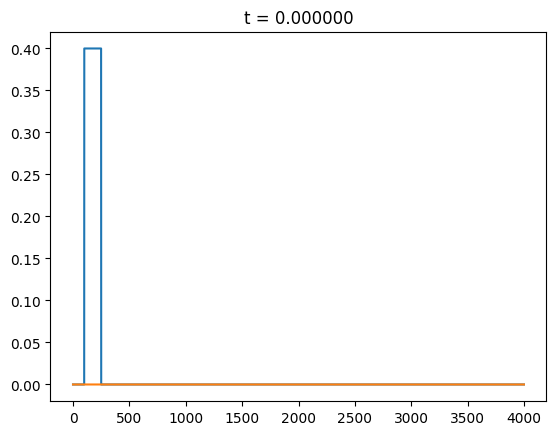

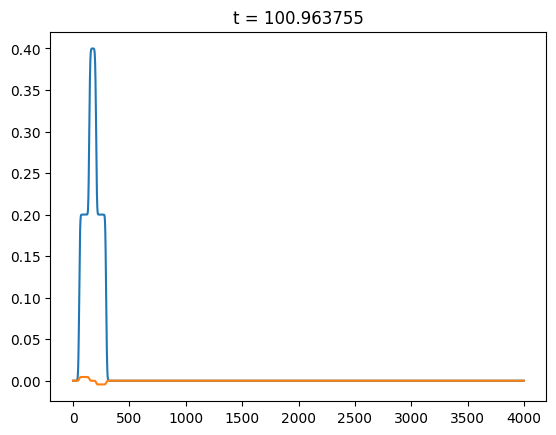

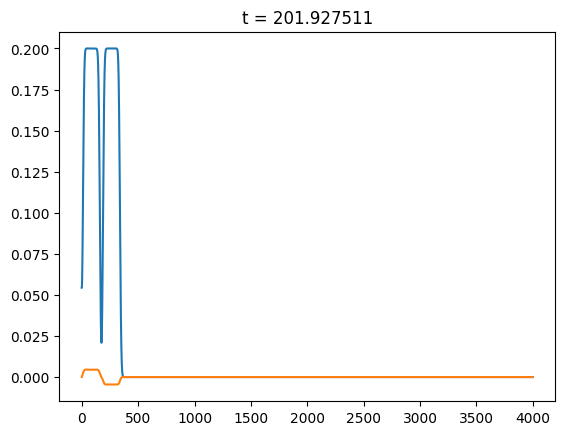

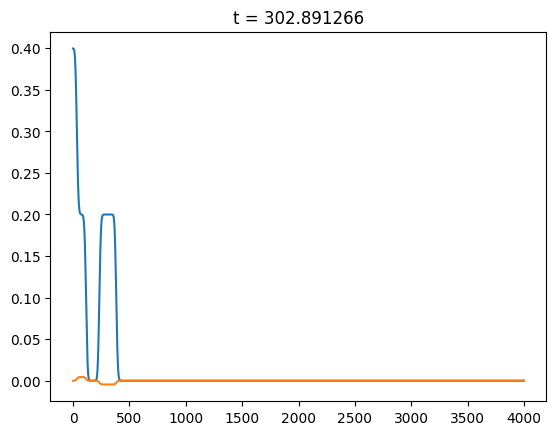

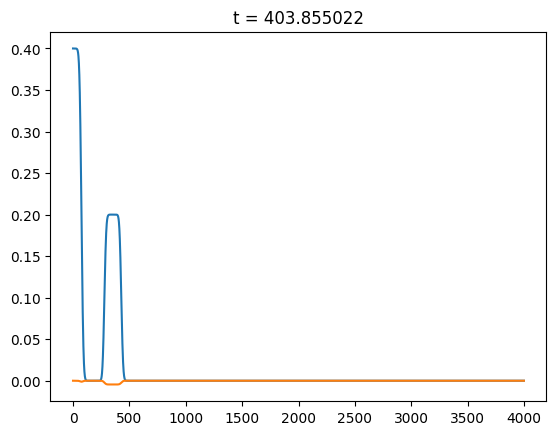

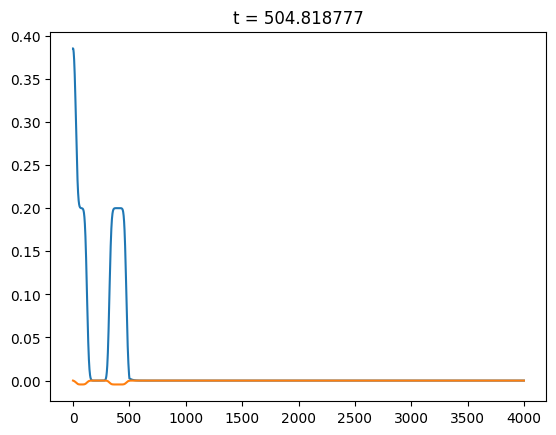

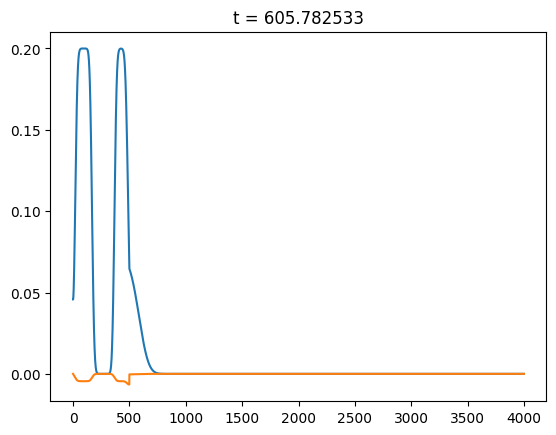

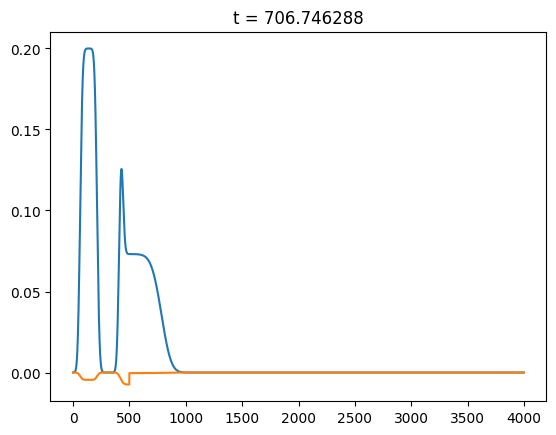

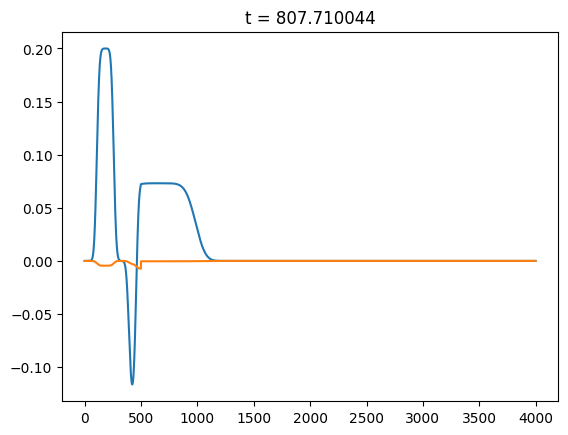

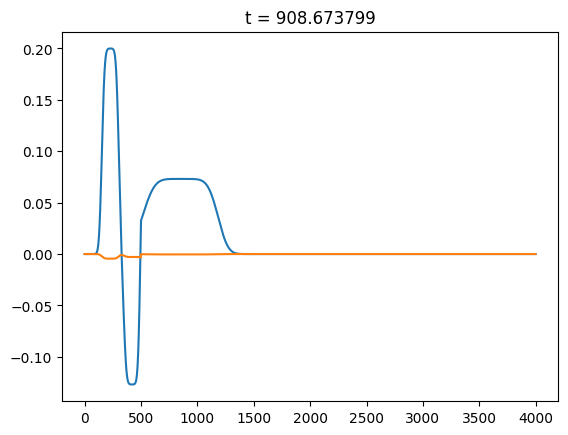

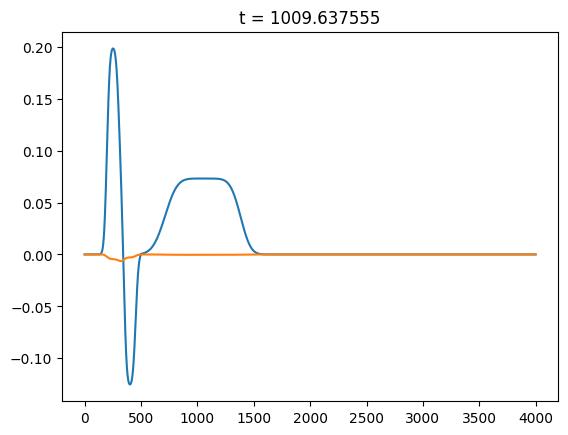

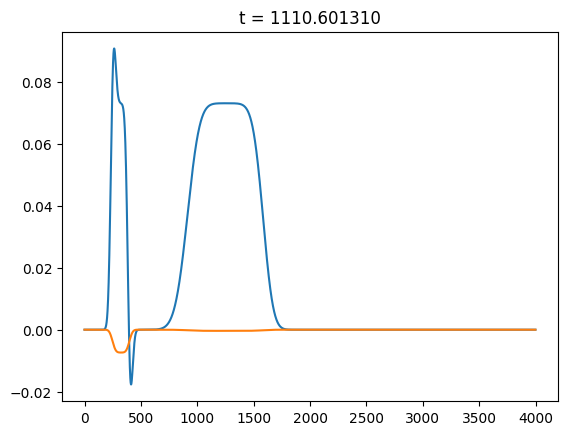

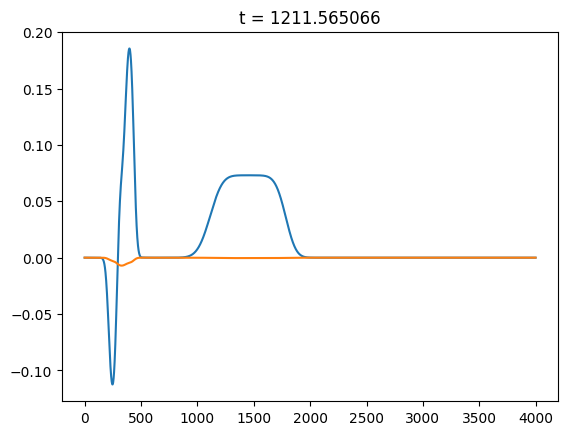

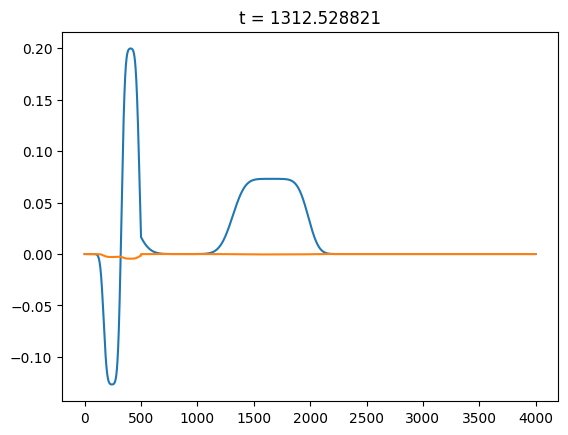

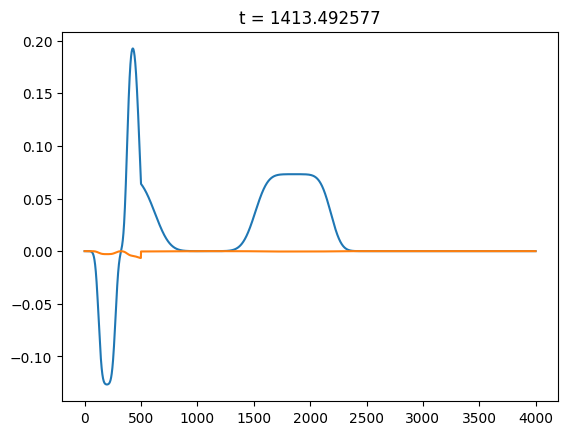

KeyboardInterrupt: 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
phi = lambda x: 1 if 10000 < x and x < 25000 else 0
x_max = 400000
dx = 100 # mesh width
g = 9.81
t_f = 4200

domain = np.linspace(start=0, stop=x_max, num=int(x_max/dx))
b_x = lambda x: -4000 if 50000 <= x else -200
b = np.array([b_x(x) for x in domain])
h = np.array([phi(x) * 0.4 - b_x(x) for x in domain])
hu = np.zeros(int(x_max/dx))

h_left_up = np.zeros(int(x_max/dx))
h_right_up = np.zeros(int(x_max/dx))
hu_left_up = np.zeros(int(x_max/dx))
hu_right_up = np.zeros(int(x_max/dx))

def compute_net_updates(h_l, h_r, hu_l, hu_r, b_l, b_r):
    if b_r >= 0 and b_l >= 0:
        return (0, 0, 0, 0, 0)
    if b_r >= 0 and b_l < 0:
        h_r = h_l
        hu_r = -hu_l
        b_r = b_l
    if b_r < 0 and b_l >= 0:
        h_l = h_r
        hu_l = -hu_r
        b_l = b_r

    if h_l == h_r and b_l == b_r and hu_l == hu_r:
        # steady state
        return (0, 0, 0, 0, 0)

    #########################################################################
    # The following code is taken from:                                     #
    # https://github.com/BrisaDavis/adjoint/releases/tag/paper1_aspublished #
    # file rp1_geoclaw_adjoint.f                                            #
    #########################################################################

    hLhat = -b_l
    hRhat = -b_r

    cL = sqrt(g * hLhat)
    cR = sqrt(g * hRhat)

    # f-wave splitting
    delta = np.zeros(3)
    delta[0] = -hu_r * (cR**2) + hu_l * (cL**2)
    delta[1] = -(h_r + b_r) + (h_l + b_l)
    delta[2] = 0

    beta = np.zeros(3)
    beta[0] = (delta[0] + cR * delta[1]) 
    beta[1] = (-delta[0] + cL * delta[1])
    beta[2] = delta[2]
    if (cL + cR) != 0:
        beta[0] = beta[0] / (cL + cR)
        beta[1] = beta[1] / (cL + cR)

    # compute waves
    fw = np.zeros((2,2))
    sw = np.zeros(2)

    fw[0][0] = cL * beta[0]
    fw[1][0] = beta[0]
    sw[0] = -cL

    fw[0][1] = -cR * beta[1]
    fw[1][1] = beta[1]
    sw[1] = cR

    amdq = np.zeros(2)
    apdq = np.zeros(2)

    # determine  left and right going fluxes
    for i in [0, 1]:
        if sw[i] < 0:
            amdq = amdq + fw.T[i]
        elif sw[i] > 0:
            apdq = apdq + fw.T[i]
        else:
            amdq = amdq + 0.5 * fw.T[i]
            apdq = apdq + 0.5 * fw.T[i]

    #########################################################################
    
    return (amdq[0], amdq[1], apdq[0], apdq[1], max(sw))

t = 0
t_count = 0
while t < t_f:
    if t_count % 500 == 0 :
        plt.title("t = %f" % t)
        plt.plot(h+b)
        plt.plot(hu)
        plt.show()
        t_count = 0
    max_wave_speed = 0
    # calculate fluxes
    for i in range(1, len(h)):
        h_left_up[i-1], hu_left_up[i-1], h_right_up[i-1], hu_right_up[i-1], edge_speed = compute_net_updates(h[i-1], h[i], hu[i-1], hu[i], b[i-1], b[i])
        max_wave_speed = max(max_wave_speed, edge_speed)
    
    max_time_step = dx / max_wave_speed * 0.4

    # wave propagation
    for i in range(1, len(h)):
        h[i] -= max_time_step / dx * (h_right_up[i-1] + h_left_up[i])
        hu[i] -= max_time_step / dx * (hu_right_up[i-1] + hu_left_up[i])

    h[0] = h[1]
    hu[0] = -hu[-1]
    h[-1] = h[-2]
    hu[-1] = -hu[-2]
   
    t = t + max_time_step
    t_count = t_count + 1

plt.title("t = %f" % t)
plt.plot(h+b)
plt.plot(hu)
plt.show()